In [1]:
import IJulia
import Base64

# The julia kernel has built in support for Revise.jl, so this is the 
# recommended approach for long-running sessions:
# https://github.com/JuliaLang/IJulia.jl/blob/9b10fa9b879574bbf720f5285029e07758e50a5e/src/kernel.jl#L46-L51

# Users should enable revise within .julia/config/startup_ijulia.jl:
# https://timholy.github.io/Revise.jl/stable/config/#Using-Revise-automatically-within-Jupyter/IJulia-1

# clear console history
IJulia.clear_history()

fig_width = 10
fig_height = 5
fig_format = :retina
fig_dpi = 96

# no retina format type, use svg for high quality type/marks
if fig_format == :retina
  fig_format = :svg
elseif fig_format == :pdf
  fig_dpi = 96
  # Enable PDF support for IJulia
  IJulia.register_mime(MIME("application/pdf"))
end

# convert inches to pixels
fig_width = fig_width * fig_dpi
fig_height = fig_height * fig_dpi

# Intialize Plots w/ default fig width/height
try
  import Plots

  # Plots.jl doesn't support PDF output for versions < 1.28.1
  # so use png (if the DPI remains the default of 300 then set to 96)
  if (Plots._current_plots_version < v"1.28.1") & (fig_format == :pdf)
    Plots.gr(size=(fig_width, fig_height), fmt = :png, dpi = fig_dpi)
  else
    Plots.gr(size=(fig_width, fig_height), fmt = fig_format, dpi = fig_dpi)
  end
catch e
  # @warn "Plots init" exception=(e, catch_backtrace())
end

# Initialize CairoMakie with default fig width/height
try
  import CairoMakie

  # CairoMakie's display() in PDF format opens an interactive window
  # instead of saving to the ipynb file, so we don't do that.
  # https://github.com/quarto-dev/quarto-cli/issues/7548
  if fig_format == :pdf
    CairoMakie.activate!(type = "png")
  else
    CairoMakie.activate!(type = string(fig_format))
  end
  CairoMakie.update_theme!(resolution=(fig_width, fig_height))
catch e
    # @warn "CairoMakie init" exception=(e, catch_backtrace())
end
  
# Set run_path if specified
try
  run_path = "L1VzZXJzL211bGxpbnNqL0Ryb3Bib3gvVGVhY2hpbmcvRUNPTjQ1MzgvbGVjdHVyZXM="
  if !isempty(run_path)
    run_path = String(Base64.base64decode(run_path))
    cd(run_path)
  end
catch e
  @warn "Run path init:" exception=(e, catch_backtrace())
end


# emulate old Pkg.installed beahvior, see
# https://discourse.julialang.org/t/how-to-use-pkg-dependencies-instead-of-pkg-installed/36416/9
import Pkg
function isinstalled(pkg::String)
  any(x -> x.name == pkg && x.is_direct_dep, values(Pkg.dependencies()))
end

# ojs_define
if isinstalled("JSON") && isinstalled("DataFrames")
  import JSON, DataFrames
  global function ojs_define(; kwargs...)
    convert(x) = x
    convert(x::DataFrames.AbstractDataFrame) = Tables.rows(x)
    content = Dict("contents" => [Dict("name" => k, "value" => convert(v)) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
elseif isinstalled("JSON")
  import JSON
  global function ojs_define(; kwargs...)
    content = Dict("contents" => [Dict("name" => k, "value" => v) for (k, v) in kwargs])
    tag = "<script type='ojs-define'>$(JSON.json(content))</script>"
    IJulia.display(MIME("text/html"), tag)
  end
else
  global function ojs_define(; kwargs...)
    @warn "JSON package not available. Please install the JSON.jl package to use ojs_define."
  end
end


# don't return kernel dependencies (b/c Revise should take care of dependencies)
nothing


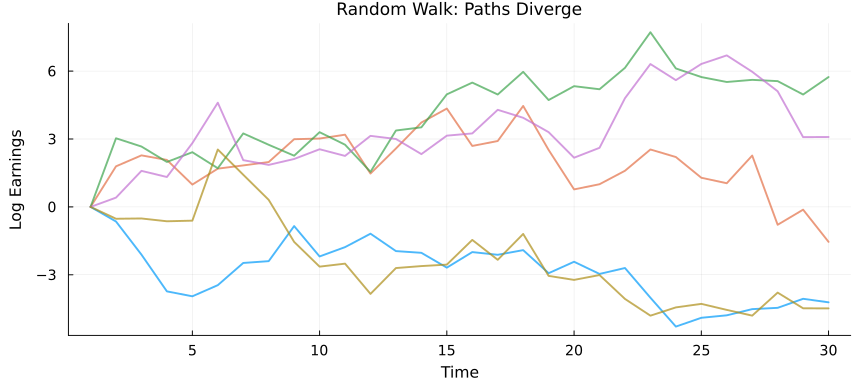

In [2]:
#| echo: true
#| output: true
#| code-fold: true

using Random, StatsPlots
Random.seed!(123)

# Simulate 5 individuals over 30 years
T = 30
N = 5
y = zeros(T, N)

for i in 1:N
    for t in 2:T
        y[t, i] = y[t-1, i] + randn()  # Random walk
    end
end

plot(1:T, y, linewidth=2, xlabel="Time", ylabel="Log Earnings",
     title="Random Walk: Paths Diverge", legend=false, alpha=0.7,
     size=(900,400), tickfontsize=10, guidefontsize=11, titlefontsize=12,
     left_margin=5Plots.mm, bottom_margin=4Plots.mm)

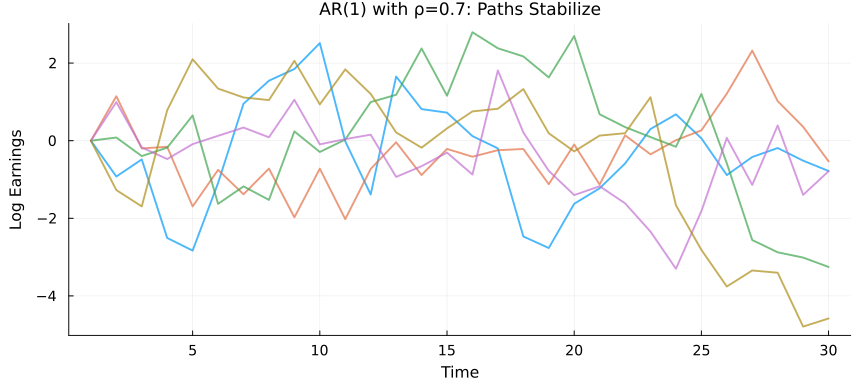

In [3]:
#| echo: true
#| output: true
#| code-fold: true

# Simulate AR(1) with ρ = 0.7
rho = 0.7
y_ar = zeros(T, N)

for i in 1:N
    for t in 2:T
        y_ar[t, i] = rho * y_ar[t-1, i] + randn()  # AR(1)
    end
end

plot(1:T, y_ar, linewidth=2, xlabel="Time", ylabel="Log Earnings",
     title="AR(1) with ρ=0.7: Paths Stabilize", legend=false, alpha=0.7,
     size=(900,400), tickfontsize=10, guidefontsize=11, titlefontsize=12,
     left_margin=5Plots.mm, bottom_margin=4Plots.mm)

In [4]:
#| echo: true
#| output: false
#| code-fold: true
#| code-line-numbers: "4-5|6|7|8|9|11-12"
using DataFrames, DataFramesMeta, CSV, StatsBase, StatsPlots
pce = @select(CSV.read("../data/PCE_index.csv",DataFrame), :INCYEAR = :YEAR, :PCE)

cps = @chain CSV.read("../data/cps_00049.csv",DataFrame,
                      select=[:YEAR,:HFLAG,:ASECWT,:AGE,:SEX,:INCWAGE,:WKSWORK1]) begin
  @subset coalesce.(:HFLAG,1) .== 1 #<- one 2014 sample (see Lecture 1)
  @transform :INCYEAR = :YEAR .- 1 #<- income refers to the previous calendar year
  @subset (:SEX .== 1) .& (:INCWAGE .> 0) .& (:WKSWORK1 .> 10) #<- men with earnings
  innerjoin(pce,on=:INCYEAR)
  @transform begin
    :logy = log.(100 .* :INCWAGE ./ :PCE) #<- log real annual earnings (2017 dollars)
    :cohort = :YEAR .- :AGE #<- approximate birth year
  end
end

Row,YEAR,HFLAG,ASECWT,AGE,SEX,WKSWORK1,INCWAGE,INCYEAR,PCE,logy,cohort
,Int64,Int64?,Float64,Int64,Int64,Int64,Int64,Int64,Float64,Float64,Int64
1,1990,missing,603.74,48,1,52,31000,1989,57.261,10.8993,1942
2,1990,missing,674.01,32,1,52,60000,1989,57.261,11.5597,1958
3,1990,missing,609.56,41,1,52,72300,1989,57.261,11.7461,1949
4,1990,missing,720.92,31,1,52,24000,1989,57.261,10.6434,1959
5,1990,missing,651.25,47,1,52,18500,1989,57.261,10.3831,1943
6,1990,missing,653.43,43,1,48,29876,1989,57.261,10.8624,1947
7,1990,missing,679.25,45,1,40,6000,1989,57.261,9.25707,1945
8,1990,missing,653.43,41,1,52,49000,1989,57.261,11.3571,1949
9,1990,missing,647.82,33,1,52,68000,1989,57.261,11.6848,1957


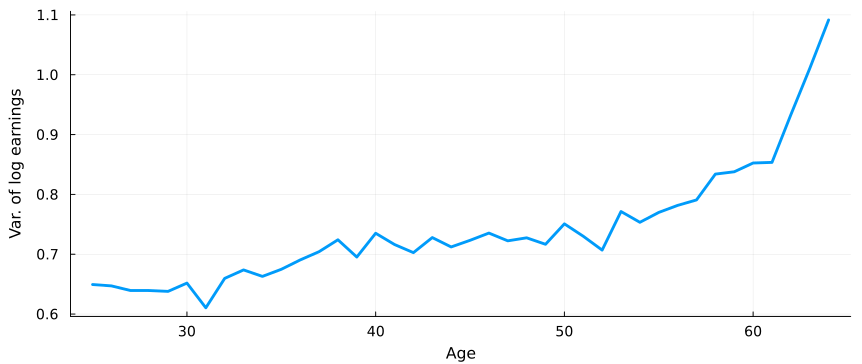

In [5]:
#| echo: true
#| code-fold: true
@chain cps begin
  groupby(:AGE)
  @combine :var_logy = var(:logy,weights(:ASECWT))
  @df _ plot(:AGE,:var_logy,linewidth=3,legend=false,
             xlabel="Age",ylabel="Var. of log earnings",
             size=(900,380),tickfontsize=10,guidefontsize=11,
             left_margin=5Plots.mm,bottom_margin=4Plots.mm)
end

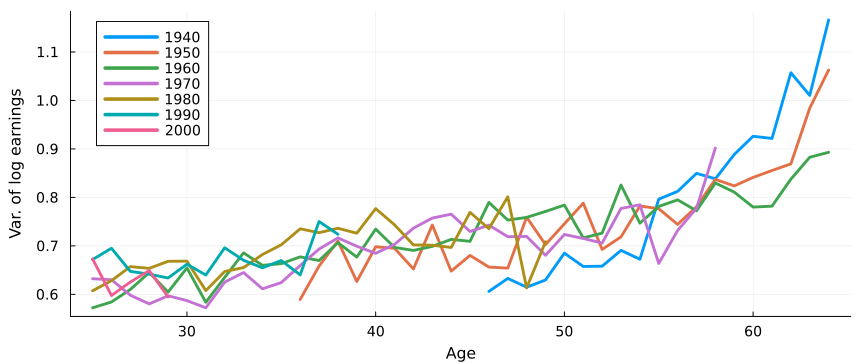

In [6]:
#| echo: true
#| code-fold: true
@chain cps begin
  @transform :cohort10 = Int.(round.(:cohort ./ 10) .* 10) #<- 10-year birth cohorts
  @subset :cohort10 .>= 1940
  groupby([:cohort10,:AGE])
  @combine :var_logy = var(:logy,weights(:ASECWT)) :N = length(:logy)
  @subset :N .> 1000
  @df _ plot(:AGE,:var_logy,group=:cohort10,linewidth=3,
             xlabel="Age",ylabel="Var. of log earnings",
             size=(900,380),tickfontsize=10,guidefontsize=11,legendfontsize=10,
             left_margin=5Plots.mm,bottom_margin=4Plots.mm)
end

In [7]:
#| echo: true
#| code-fold: true
#| output: asis
#| code-line-numbers: "1-6|8-13|15-18"
cells = @chain cps begin
  @subset 25 .<= :AGE .<= 55
  groupby([:INCYEAR,:AGE])
  @combine :var_logy = var(:logy,weights(:ASECWT))
  @transform :cohort = :INCYEAR .- :AGE
end

# OLS slope on age, with a full set of dummies for the variable `fe`
function age_slope(d, fe)
  lev = sort(unique(d[!,fe]))[2:end]   #<- drop one category
  D = Float64.(d[!,fe] .== permutedims(lev)) #<- matrix of dummies
  X = [ones(nrow(d)) d.AGE D]
  return (X \ d.var_logy)[2] #<- coefficient on age
end

println("| Controls | Slope on age |\n|:--|--:|")
for (lab,fe) in [("Year effects",:INCYEAR),("Cohort effects",:cohort)]
  println("| ", lab, " | ", round(age_slope(cells,fe),digits=4), " |")
end

| Controls | Slope on age |
|:--|--:|
| Year effects

 | 0.0043 |
| Cohort effects | 0.0062 |


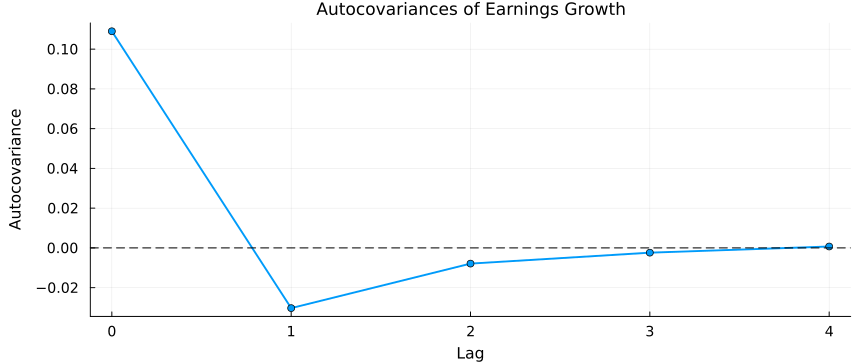

In [8]:
#| echo: false
#| output: true

using DataFrames, StatsPlots

# Autocovariances of earnings growth
orders = 0:4
pooled_autocov = [0.109, -0.0303, -0.0079, -0.0024, 0.0007]

plot(orders, pooled_autocov,
     marker=:circle,
     linewidth=2,
     xlabel="Lag",
     ylabel="Autocovariance",
     title="Autocovariances of Earnings Growth",
     legend=false,
     grid=true,
     size=(900,380), tickfontsize=10, guidefontsize=11, titlefontsize=12,
     left_margin=5Plots.mm, bottom_margin=4Plots.mm)
hline!([0], linestyle=:dash, color=:black, linewidth=1)

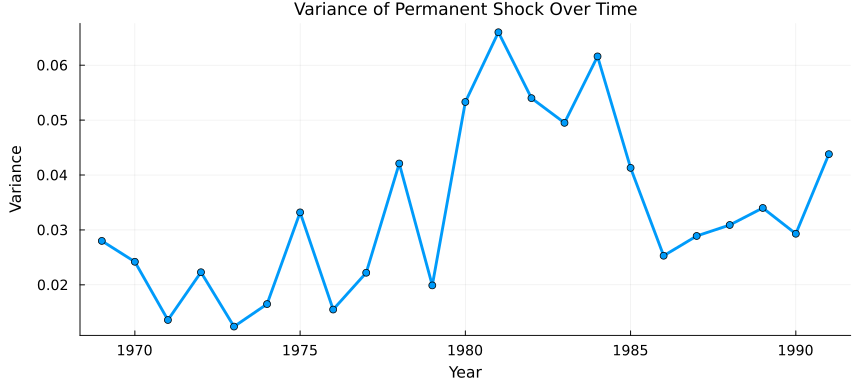

In [9]:
#| echo: false
#| output: true

years = 1969:1991
var_perm = [0.0280, 0.0242, 0.0136, 0.0223, 0.0124, 0.0165, 0.0332,
            0.0155, 0.0222, 0.0421, 0.0199, 0.0533, 0.0660, 0.0540,
            0.0495, 0.0616, 0.0413, 0.0253, 0.0289, 0.0309, 0.0340,
            0.0293, 0.0438]

plot(years, var_perm,
     linewidth=3,
     marker=:circle,
     xlabel="Year",
     ylabel="Variance",
     title="Variance of Permanent Shock Over Time",
     legend=false,
     grid=true,
     size=(900,400), tickfontsize=10, guidefontsize=11, titlefontsize=12,
     left_margin=5Plots.mm, bottom_margin=4Plots.mm)